# Solutions to the exercises of Chapter 2

Sample solutions for [Chapter 2, Steady conduction and thermal resistance](../../notebooks/part1_conduction/02_steady_conduction.ipynb).

In [1]:
import math

import matplotlib.pyplot as plt
import numpy as np
from scipy.integrate import cumulative_trapezoid

try:
    from engtransport import numerics, properties, reference
except ImportError:          # running from a clone without `pip install -e .`
    import sys
    sys.path.insert(0, "../..")
    from engtransport import numerics, properties, reference
from engtransport.constants import SIGMA_SB
from engtransport.plotting import use_style

use_style()

h_i, h_o, T_i, T_o = 8.0, 23.0, 273.15 + 20.0, 273.15 - 35.0
T_dew = properties.dew_point(T_i, 0.50)

## Exercise 1. A window

The resistances per unit area add as in Eq. (2.1). With the air gap treated as a still,
conducting layer:

In [2]:
def glazing(R_layers):
    R = 1 / h_i + sum(R_layers) + 1 / h_o
    U = 1 / R
    return U, T_i - U * (T_i - T_o) / h_i


U2, T2 = glazing([0.004 / 1.0, 0.016 / 0.025, 0.004 / 1.0])
U1, T1 = glazing([0.004 / 1.0])
print(f"double glazing, conduction only: U = {U2:.2f} W/(m2 K), inner pane {T2 - 273.15:5.1f} C")
print(f"single glazing:                  U = {U1:.2f} W/(m2 K), inner pane {T1 - 273.15:5.1f} C")
print(f"dew point of the room air: {T_dew - 273.15:.1f} C")

# radiation across the gap between two uncoated panes (emissivity 0.84), linearised at the
# temperature in the middle of the gap, which is found by fixed-point iteration
T_gap = 0.5 * (T2 + T_o)
for _ in range(20):
    h_rad = 4 * SIGMA_SB * T_gap**3 / (2 / 0.84 - 1)
    U_r, T_in = glazing([0.004, 1 / (0.025 / 0.016 + h_rad), 0.004])
    q = U_r * (T_i - T_o)
    T_gap = T_in - q * (0.004 + 0.5 / (0.025 / 0.016 + h_rad))
print(f"with radiation across the gap: h_r = {h_rad:.2f} W/(m2 K), U = {U_r:.2f} W/(m2 K),"
      f" inner pane {T_in - 273.15:.1f} C")

double glazing, conduction only: U = 1.22 W/(m2 K), inner pane  11.6 C
single glazing:                  U = 5.80 W/(m2 K), inner pane -19.9 C
dew point of the room air: 9.3 C
with radiation across the gap: h_r = 2.89 W/(m2 K), U = 2.49 W/(m2 K), inner pane 2.9 C


Treated as a still conductor, the air gap would give $U = 1.2$ W/(m² K), and the inner pane
would stay at 11.6 °C, above the dew point. Single glazing has $U = 5.8$ W/(m² K) and an
inner surface far below freezing: it frosts over, as anyone who has lived in an old flat in
Astana knows.

The conduction-only model is too optimistic because the gap also passes heat by radiation
between the panes and by slow convection. With uncoated glass ($\varepsilon \approx 0.84$),
radiation alone adds 2.9 W/(m² K) across the gap, nearly twice what the air conducts,
and brings $U$ to 2.5 W/(m² K); convection in the gap supplies the rest of the measured 2.8.
The inner pane is then at about 3 °C, below the dew point, and on a night at −35 °C even
double glazing mists up, first at its edges.
This is why modern windows use low-emissivity coatings and argon fillings: they attack
radiation and convection, not conduction.

## Exercise 2. A sphere

For a spherical shell, $R = (1/r_1 - 1/r_2)/4\pi k$ and the outer resistance is
$1/(4\pi r_2^2 h)$. The total resistance has its minimum where

$$ \frac{d}{dr_2}\left[\frac{1}{4\pi k}\left(\frac{1}{r_1} - \frac{1}{r_2}\right) + \frac{1}{4\pi h r_2^2}\right]
= \frac{1}{4\pi}\left(\frac{1}{k r_2^2} - \frac{2}{h r_2^3}\right) = 0
\quad\Rightarrow\quad r_{\rm cr} = \frac{2k}{h}. $$

For the epoxy and $h = 50$ W/(m² K), $r_{\rm cr} = 8$ mm. A bead that generates $P$ is
warmer than the air by $P R_{\rm tot}$:

In [3]:
P, r1, k_ep, h = 2e-3, 0.5e-3, 0.2, 50.0
print(f"critical radius 2k/h = {1e3 * 2 * k_ep / h:.0f} mm")
print(f"bare bead: self-heating {P / (4 * math.pi * r1**2 * h):.2f} K")
for r2 in (1e-3, 2e-3, 8e-3, 20e-3):
    R = (1 / r1 - 1 / r2) / (4 * math.pi * k_ep) + 1 / (4 * math.pi * r2**2 * h)
    print(f"coated to r2 = {1e3 * r2:4.0f} mm: self-heating {P * R:.2f} K")

critical radius 2k/h = 8 mm
bare bead: self-heating 12.73 K
coated to r2 =    1 mm: self-heating 3.98 K
coated to r2 =    2 mm: self-heating 1.99 K
coated to r2 =    8 mm: self-heating 1.54 K
coated to r2 =   20 mm: self-heating 1.56 K


The bare bead reads 12.7 K too warm. Because it is far smaller than the critical radius,
a coat of epoxy lowers the total resistance: the error falls to 4.0 K at 1 mm and 2.0 K at
2 mm, and is smallest, 1.5 K, at $r_2 = 8$ mm. A thicker coat would also make the sensor
slower to follow the air temperature (Chapter 5), so in practice the power is reduced
instead.

## Exercise 3. The whole fuel rod

From the water inwards, each resistance per metre is crossed by the whole $q'$:

In [4]:
q_lin = 20e3
r_p, r_ci, r_co = 4.1e-3, 4.18e-3, 4.75e-3
T_water, h_w, h_gap, k_zr = 273.15 + 310.0, 30000.0, 5000.0, 16.0
T_co = T_water + q_lin / (2 * math.pi * r_co * h_w)
T_ci = T_co + q_lin * math.log(r_co / r_ci) / (2 * math.pi * k_zr)
T_ps = T_ci + q_lin / (2 * math.pi * r_p * h_gap)
T_grid = np.linspace(T_ps, 3000.0, 20001)
Theta = cumulative_trapezoid(properties.uo2_conductivity(T_grid), T_grid, initial=0.0)
T_c = np.interp(q_lin / (4 * math.pi), Theta, T_grid)
steps = [("water", T_water), ("tube, water side", T_co), ("tube, inside", T_ci), ("pellet surface", T_ps),
         ("pellet centre", T_c)]
for (name, T), (_, T_prev) in zip(steps, [steps[0]] + steps[:-1]):
    print(f"{name:18s} {T - 273.15:7.1f} C   (+{T - T_prev:6.1f} K)")

water                310.0 C   (+   0.0 K)
tube, water side     332.3 C   (+  22.3 K)
tube, inside         357.8 C   (+  25.4 K)
pellet surface       513.0 C   (+ 155.3 K)
pellet centre        973.4 C   (+ 460.4 K)


The temperature rises by 22 K through the water film, 25 K across the zirconium-alloy
tube, 155 K across the gas gap and 460 K inside the pellet, whose surface is at 513 °C,
close to the value used in Section 2.4. Outside the pellet the gap dominates: its
conductance changes during the life of the rod as the pellet swells and the gas
composition changes, which is why fuel performance codes spend so much effort on it.

## Exercise 4. The insulation of Chapter 1 again

For $k = k_0[1 + \beta(T - T_0)]$, the Kirchhoff integral across the insulation is
$k(\bar T)(T_w - T_s)$ with $\bar T = (T_w + T_s)/2$, so the heat loss is Eq. (1.5) with $k$
at the mean temperature of the insulation. The surface balance (1.6) then contains $T_s$
both in the radiation term and in $k(\bar T)$; Newton's method with a numerical derivative
solves it.

mean temperature of the wool 39.1 C, k there 0.0415 W/(m K)
heat loss with k(T): 58.81 W/m (Chapter 1 with k = 0.045: 63.70 W/m)
finite volumes, 200 cells: 58.8071 W/m (mean-temperature rule 58.8072 W/m)


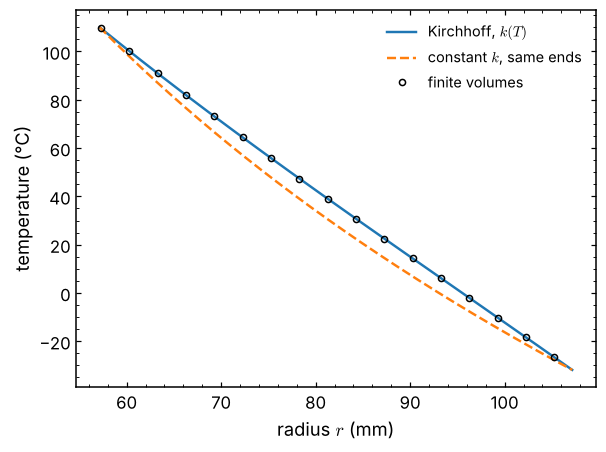

In [5]:
r_1, r_2, eps, h_air = 0.05715, 0.10715, 0.9, 25.0
T_w, T_inf = 273.15 + 110.0, 273.15 - 35.0
k_wool = lambda T: 0.036 + (0.050 - 0.036) * (T - 273.15) / 100.0


def balance(Ts):
    q = 2 * math.pi * k_wool(0.5 * (T_w + Ts)) * (T_w - Ts) / math.log(r_2 / r_1)
    return q - 2 * math.pi * r_2 * (h_air * (Ts - T_inf) + eps * SIGMA_SB * (Ts**4 - T_inf**4))


dbalance = lambda Ts: (balance(Ts + 1e-4) - balance(Ts - 1e-4)) / 2e-4
T_s, _ = numerics.newton(balance, dbalance, x0=T_inf)
q_kT = 2 * math.pi * k_wool(0.5 * (T_w + T_s)) * (T_w - T_s) / math.log(r_2 / r_1)
print(f"mean temperature of the wool {0.5 * (T_w + T_s) - 273.15:.1f} C, k there {k_wool(0.5 * (T_w + T_s)):.4f} W/(m K)")
print(f"heat loss with k(T): {q_kT:.2f} W/m (Chapter 1 with k = 0.045: 63.70 W/m)")

fv = reference.steady_conduction_fv(np.linspace(r_1, r_2, 201), lambda T, i: k_wool(T), "cylinder",
                                    left=("temperature", T_w), right=("convection", h_air, T_inf, eps, T_inf))
print(f"finite volumes, 200 cells: {fv['Q_right']:.4f} W/m (mean-temperature rule {q_kT:.4f} W/m)")

r = np.linspace(r_1, r_2, 200)
Theta_r = (T_w - T_s) * k_wool(0.5 * (T_w + T_s)) * np.log(r / r_1) / np.log(r_2 / r_1)
# invert Theta(T) = integral of k from T_w down to T (k linear: a quadratic in T)
a, b = 0.5 * 0.00014, 0.036 - 0.00014 * 273.15
T_exact = (-b + np.sqrt(b**2 + 4 * a * (a * T_w**2 + b * T_w - Theta_r))) / (2 * a)
fig, ax = plt.subplots(figsize=(5.4, 4.0))
ax.plot(r * 1e3, T_exact - 273.15, "C0", label="Kirchhoff, $k(T)$")
ax.plot(r * 1e3, T_w - 273.15 - (T_w - T_s) * np.log(r / r_1) / np.log(r_2 / r_1), "C1--", label="constant $k$, same ends")
ax.plot(fv["r"][::12] * 1e3, fv["T"][::12] - 273.15, "ko", ms=4, mfc="none", label="finite volumes")
ax.set_xlabel(r"radius $r$ (mm)")
ax.set_ylabel("temperature (°C)")
ax.legend(loc="upper right")
plt.show()

**Figure S2.1.** Temperature through the mineral wool of the pipe of Chapter 1 with a
conductivity that rises with temperature: the exact profile from the Kirchhoff transform,
the logarithm of constant conductivity between the same end temperatures, and finite
volumes.

The insulation is at 39 °C on average, where $k = 0.0415$ W/(m K), so the pipe loses
58.8 W/m, 8 % less than with the constant value of Chapter 1. The finite volumes agree to
five digits. The profile bends: where the wool is hot it conducts better and needs a
smaller gradient, so the temperature stays higher near the pipe than the logarithm of
constant conductivity would give.